In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv('Housing.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [5]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (545, 13)

Column Names:
Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea       

In [7]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [8]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate Records:
0


In [9]:
df = df.drop_duplicates()

print("Duplicate records removed successfully!")
print("Updated Dataset Shape:", df.shape)

Duplicate records removed successfully!
Updated Dataset Shape: (545, 13)


In [10]:
# House Price Analysis

print("Average House Price:", df['price'].mean())

print("Minimum House Price:", df['price'].min())

print("Maximum House Price:", df['price'].max())

Average House Price: 4766729.247706422
Minimum House Price: 1750000
Maximum House Price: 13300000


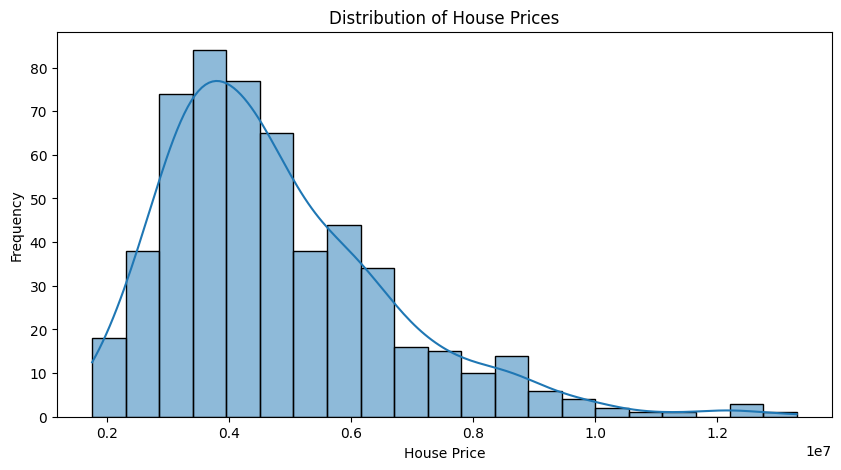

In [11]:
plt.figure(figsize=(10,5))

sns.histplot(df['price'], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

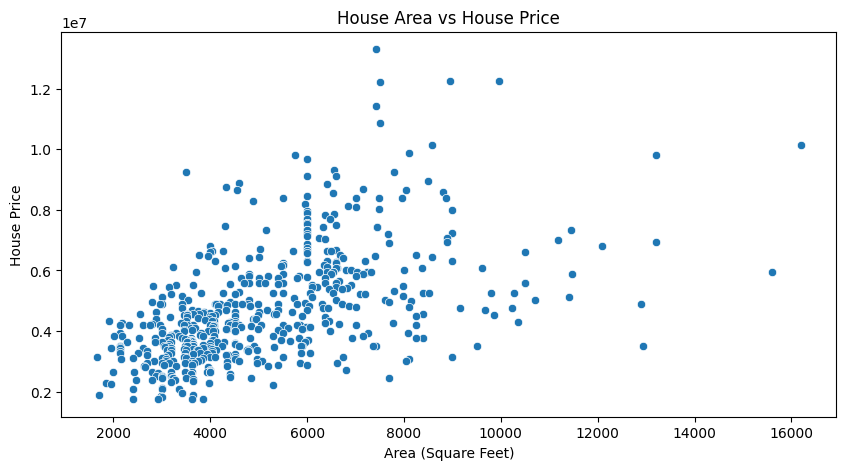

In [12]:
plt.figure(figsize=(10,5))

sns.scatterplot(x='area', y='price', data=df)

plt.title("House Area vs House Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("House Price")

plt.show()

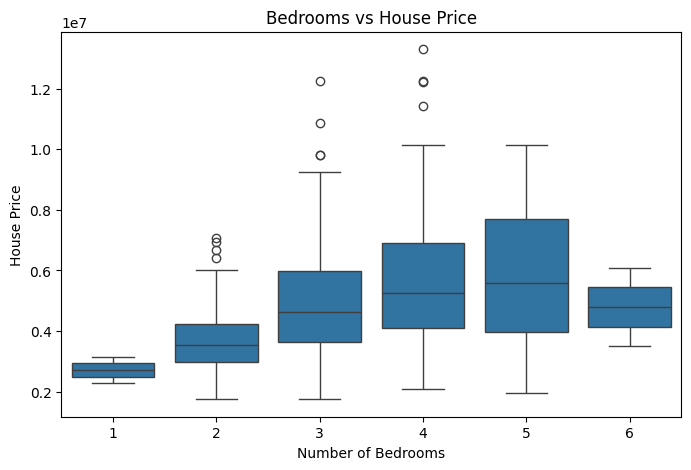

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(x='bedrooms', y='price', data=df)

plt.title("Bedrooms vs House Price")
plt.xlabel("Number of Bedrooms")
plt.ylabel("House Price")

plt.show()

In [14]:
# Convert categorical columns into numerical values

df = pd.get_dummies(df, drop_first=True, dtype=int)

print("Categorical data converted successfully!")

df.head()

Categorical data converted successfully!


,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,12250000,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,12250000,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,12215000,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,11410000,7420,4,1,2,2,1,1,1,0,1,0,0,0


In [15]:
# Separate features and target

X = df.drop('price', axis=1)

y = df['price']

print("Features separated successfully!")

print("X Shape:", X.shape)

print("y Shape:", y.shape)

Features separated successfully!
X Shape: (545, 13)
y Shape: (545,)


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training and Testing Data Split Successfully!")

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training and Testing Data Split Successfully!
Training Data: (436, 13)
Testing Data: (109, 13)


In [17]:
# Create Linear Regression Model

model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [18]:
# Predict house prices

y_pred = model.predict(X_test)

print("House Price Predictions:")
print(y_pred[:10])

House Price Predictions:
[5164653.90033967 7224722.29802166 3109863.24240338 4612075.32722559
 3294646.25725955 3532275.09556558 5611774.56836476 6368145.98732718
 2722856.95689985 2629405.61585782]


In [19]:
# Evaluate Model Performance

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

Model Evaluation Results
MAE: 970043.4039201636
MSE: 1754318687330.6638
RMSE: 1324506.9600914386
R2 Score: 0.6529242642153184


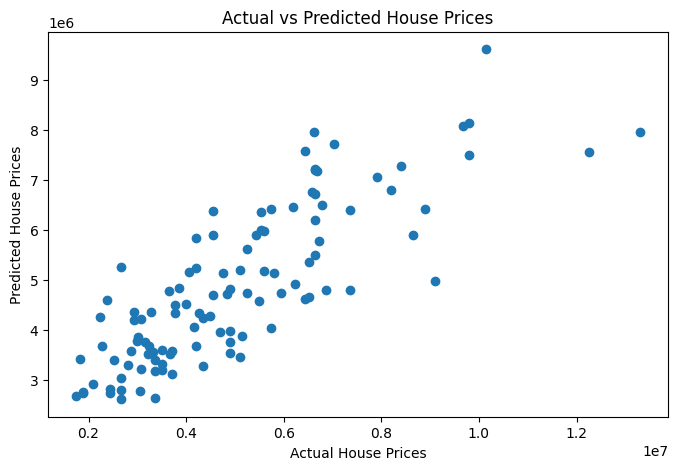

In [20]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [21]:
# Predict price for a new house

new_house = pd.DataFrame([{
    'area': 5000,
    'bedrooms': 3,
    'bathrooms': 2,
    'stories': 2,
    'mainroad_yes': 1,
    'guestroom_yes': 0,
    'basement_yes': 0,
    'hotwaterheating_yes': 0,
    'airconditioning_yes': 1,
    'parking': 2,
    'prefarea_yes': 1,
    'furnishingstatus_semi-furnished': 0,
    'furnishingstatus_unfurnished': 0
}])

# Match training feature columns
new_house = new_house.reindex(columns=X.columns, fill_value=0)

predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 6912976.322777912


In [22]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,4060000,5.164654e+06
1,6650000,7.224722e+06
2,3710000,3.109863e+06
3,6440000,4.612075e+06
4,2800000,3.294646e+06
5,4900000,3.532275e+06
6,5250000,5.611775e+06
7,4543000,6.368146e+06
8,2450000,2.722857e+06
9,3353000,2.629406e+06


In [23]:
# Feature Importance

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.coef_
})

importance = importance.sort_values(
    by='Importance',
    key=abs,
    ascending=False
)

print(importance)

                            Feature    Importance
2                         bathrooms  1.094445e+06
9               airconditioning_yes  7.914267e+05
8               hotwaterheating_yes  6.846499e+05
10                     prefarea_yes  6.298906e+05
12     furnishingstatus_unfurnished -4.136451e+05
3                           stories  4.074766e+05
7                      basement_yes  3.902512e+05
5                      mainroad_yes  3.679199e+05
6                     guestroom_yes  2.316100e+05
4                           parking  2.248419e+05
11  furnishingstatus_semi-furnished -1.268818e+05
1                          bedrooms  7.677870e+04
0                              area  2.359688e+02


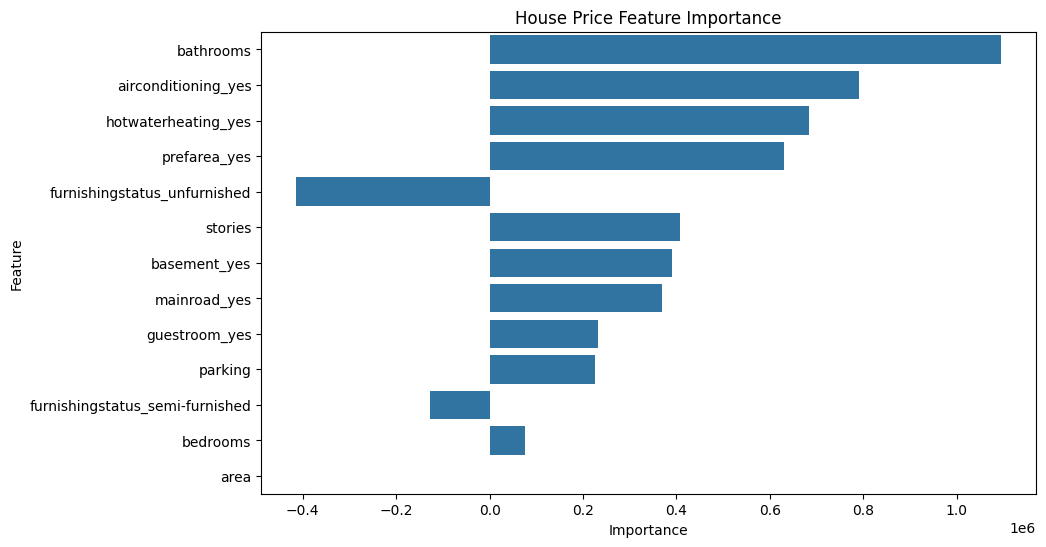

In [24]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("House Price Feature Importance")
plt.show()

In [26]:
df.to_csv('House_Price_Predictions.csv', index=False)